**Цель работы:**

Изучение алгоритмов и методов кластеризации на практике.

# Лабораторная работа 4. Кластеризация

### Описание предметной области

**Вариант №4**

Работа состоит из двух частей:
- **Часть 1:** кластеризация искусственно созданных данных с двумя признаками `x` и `y`. Функция `make_data(n, seed)` формирует три группы по `n` объектов.
- **Часть 2:** кластеризация заёмщиков на основе набора `bank_loan_default.csv` и сравнение методов K-means и агломеративной иерархической кластеризации.

Набор `bank_loan_default.csv` содержит сведения о кредитах. Его атрибуты:
- `age` — возраст заёмщика (лет);
- `annual_income` — годовой доход (USD);
- `employment_type` — тип занятости (`Salaried`, `Self-Employed`, `Unemployed`);
- `education` — уровень образования (`HS`, `Bachelors`, `Masters`, `PhD`);
- `loan_amount` — сумма кредита (USD);
- `interest_rate_pct` — годовая процентная ставка (%);
- `term_months` — срок кредита (месяцев);
- `credit_score` — кредитный рейтинг;
- `num_open_accounts` — количество открытых кредитных счетов;
- `delinquency_30d` — наличие просрочки платежа на 30 дней (`Yes` / `No`);
- `residence_type` — тип жилья (`Own`, `Rent`, `Mortgage`);
- `Default` — исходный целевой класс: **1 — дефолт по кредиту, 0 — дефолта нет**.

Кластеризация относится к обучению **без учителя**: алгоритм получает только признаки объектов, но не истинный класс `Default`. Этот столбец используется исключительно **после кластеризации**, чтобы сопоставить полученные группы с известными классами.

## 1. Часть 1. Кластеризация искусственно созданных данных

### 1.1 Подключение библиотек и создание набора данных

*Использовать предложенную функцию `make_data(n, seed)` для получения трёх групп наблюдений с признаками `x` и `y`.*

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    fowlkes_mallows_score,
)
from scipy.cluster.hierarchy import dendrogram, linkage

# Для воспроизводимости результатов используются фиксированные seed и random_state.
RANDOM_STATE = 4

In [2]:
# Функция создания данных из методических указаний.
def make_data(n, seed):
    np.random.seed(seed)

    shift_matrix = np.array([[3, 3],
                             [6, 9],
                             [9, 3]])

    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])

    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    df = df.sample(frac=1.0, random_state=seed)
    return df

# По 100 наблюдений в каждой из трёх групп.
df_generated = make_data(n=100, seed=RANDOM_STATE)
print('Размер набора данных:', df_generated.shape)
display(df_generated.head())

Размер набора данных: (300, 2)


,x,y
293,147.909730,0.823323
166,113.309213,4.194715
18,74.466832,1.806766
43,59.812798,1.054512
241,188.093868,1.691913


Получен DataFrame из **300 объектов и 2 числовых признаков** (`x`, `y`). Известно, что при создании данных заложено три группы по 100 объектов, однако сами метки этих групп алгоритму кластеризации не передаются. Для перемешивания строк дополнительно зафиксирован `random_state=4`.

### 1.2 Стандартизация числовых признаков

*Перед использованием алгоритма K-means привести `x` и `y` к сопоставимому масштабу с помощью `StandardScaler`.*

In [3]:
scaler_generated = StandardScaler()
X_generated_scaled = scaler_generated.fit_transform(df_generated[['x', 'y']])

df_generated_scaled = pd.DataFrame(
    X_generated_scaled, columns=['x', 'y'], index=df_generated.index
)
display(df_generated_scaled.describe().round(3))

,x,y
count,300.000,300.000
mean,-0.000,-0.000
std,1.002,1.002
min,-2.070,-1.360
25%,-0.936,-0.797
50%,-0.021,-0.439
75%,0.889,1.158
max,1.962,2.218


Стандартизация необходима, поскольку координата `x` имеет существенно больший числовой масштаб, чем `y`. После применения `StandardScaler` средние значения обоих признаков близки к нулю, а стандартные отклонения — к единице. Это позволяет учитывать оба признака при вычислении расстояний.

### 1.3 K-means с тремя кластерами

*Применить `fit_predict()` для `n_clusters=3` и получить метки кластеров.*

In [4]:
kmeans_generated_3 = KMeans(
    n_clusters=3, n_init=10, random_state=RANDOM_STATE
)
labels_generated_3 = kmeans_generated_3.fit_predict(X_generated_scaled)

df_generated_3 = df_generated.copy()
df_generated_3['cluster'] = labels_generated_3

print('Число объектов в каждом кластере:')
display(df_generated_3['cluster'].value_counts().sort_index())
print('Пример полученных меток:')
display(df_generated_3.head(10))

Число объектов в каждом кластере:


cluster
0    100
1    100
2    100
Name: count, dtype: int64

Пример полученных меток:


,x,y,cluster
293,147.909730,0.823323,2
166,113.309213,4.194715,1
18,74.466832,1.806766,0
43,59.812798,1.054512,0
241,188.093868,1.691913,2
192,175.542694,4.641103,1
147,113.990694,4.887734,1
202,204.010176,2.407926,2
13,66.645063,1.283057,0
233,179.561869,2.129581,2


Алгоритм выделил **три кластера по 100 объектов**. Номера кластеров (`0`, `1`, `2`) являются условными: важна принадлежность объектов к одной группе, а не числовое значение её метки.

### 1.4 Визуализация кластеров и их центров

*Построить диаграмму рассеивания, выделив кластеры разными цветами и отметив центроиды.*

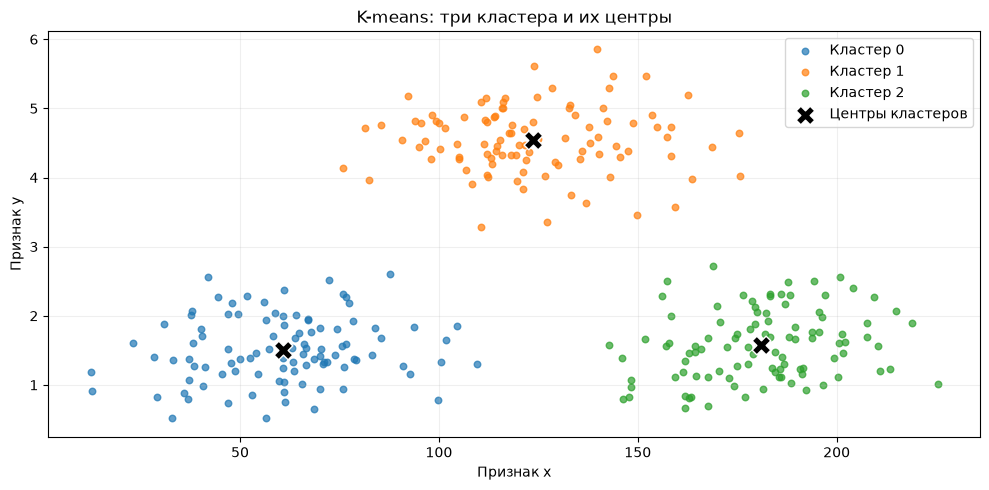

In [5]:
# Центры модели вычислены по стандартизованным данным.
# Для графика в исходных единицах выполняется обратное преобразование.
centers_generated_3 = scaler_generated.inverse_transform(
    kmeans_generated_3.cluster_centers_
)

plt.figure(figsize=(10, 5))
for cluster in range(3):
    points = df_generated_3[df_generated_3['cluster'] == cluster]
    plt.scatter(points['x'], points['y'], s=22, alpha=0.7, label=f'Кластер {cluster}')

plt.scatter(
    centers_generated_3[:, 0], centers_generated_3[:, 1],
    marker='X', s=180, color='black', edgecolors='white',
    linewidths=1, label='Центры кластеров', zorder=5
)
plt.title('K-means: три кластера и их центры')
plt.xlabel('Признак x')
plt.ylabel('Признак y')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

На диаграмме наблюдаются **три хорошо разделённые группы точек**. Чёрными маркерами обозначены центры кластеров, вычисленные алгоритмом. Для наглядности координаты центров преобразованы обратно из стандартизованного масштаба в исходные единицы `x` и `y`.

### 1.5 Коэффициент силуэта для трёх кластеров

*Оценить качество разделения объектов с помощью `silhouette_score`.*

In [6]:
silhouette_generated_3 = silhouette_score(
    X_generated_scaled, labels_generated_3
)
print(f'Коэффициент силуэта при k=3: {silhouette_generated_3:.4f}')

Коэффициент силуэта при k=3: 0.7097


Коэффициент силуэта составляет **0,7097**. Это положительное и достаточно высокое значение: объекты в среднем заметно ближе к своим кластерам, чем к соседним группам.

### 1.6 Сравнение K-means для двух, трёх и четырёх кластеров

*Повторить кластеризацию, визуализацию и вычисление силуэта для `n_clusters=2` и `n_clusters=4`; сопоставить с результатом `n_clusters=3`.*

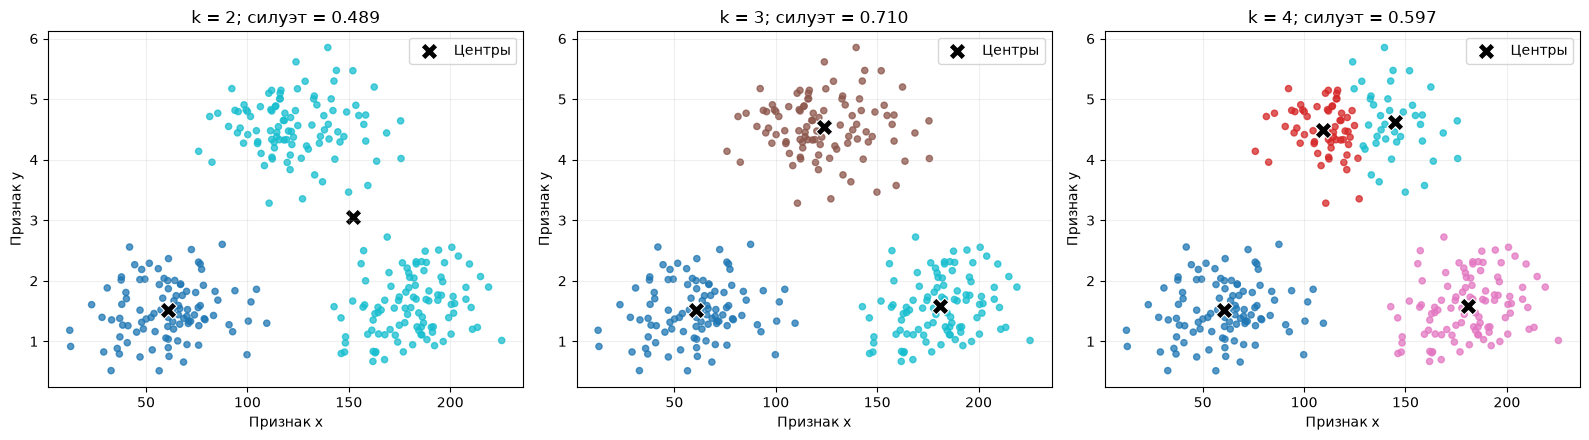

,Число кластеров,Силуэт
0,2,0.4889
1,3,0.7097
2,4,0.5970


In [7]:
generated_comparison = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, k in zip(axes, [2, 3, 4]):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_generated_scaled)
    score = silhouette_score(X_generated_scaled, labels)
    generated_comparison.append({'Число кластеров': k, 'Силуэт': score})

    centers = scaler_generated.inverse_transform(model.cluster_centers_)
    ax.scatter(df_generated['x'], df_generated['y'], c=labels, cmap='tab10', s=20, alpha=0.75)
    ax.scatter(
        centers[:, 0], centers[:, 1], marker='X', color='black',
        edgecolors='white', linewidths=0.8, s=145, label='Центры'
    )
    ax.set_title(f'k = {k}; силуэт = {score:.3f}')
    ax.set_xlabel('Признак x')
    ax.set_ylabel('Признак y')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

display(pd.DataFrame(generated_comparison).round(4))

Для **k=2** получен силуэт **0,4889**: алгоритм объединяет две исходные группы в одну. Для **k=4** силуэт составляет **0,5970**: одна из естественных групп разделяется на части. Наиболее высокий коэффициент силуэта (**0,7097**) достигнут при **k=3**, что соответствует структуре созданного набора данных.

### 1.7 Метод локтя

*Построить зависимость внутрикластерной суммы квадратов расстояний (`inertia_`) от числа кластеров.*

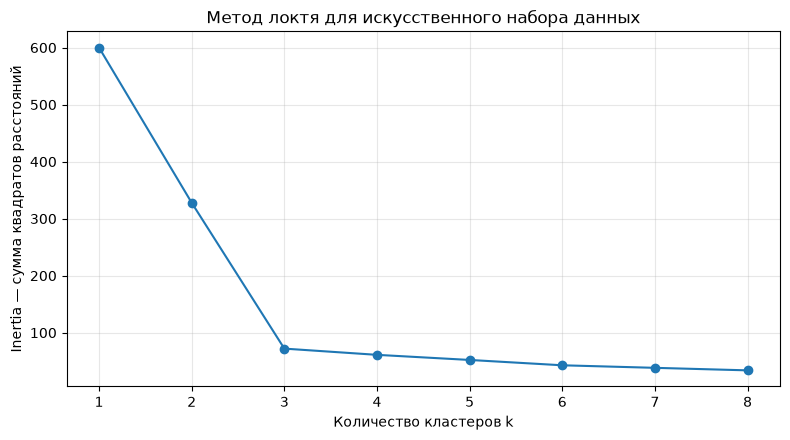

In [8]:
generated_inertia = []
ks_generated = range(1, 9)

for k in ks_generated:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    model.fit(X_generated_scaled)
    generated_inertia.append(model.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(list(ks_generated), generated_inertia, marker='o')
plt.xticks(list(ks_generated))
plt.xlabel('Количество кластеров k')
plt.ylabel('Inertia — сумма квадратов расстояний')
plt.title('Метод локтя для искусственного набора данных')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

На графике наблюдается выраженное снижение `inertia_` при увеличении числа кластеров до **трёх**. После k=3 уменьшение становится значительно более плавным. Метод локтя и коэффициент силуэта согласованно указывают на **оптимальное k=3**.

### 1.8 Вывод по первой части

Для 300 искусственных наблюдений выполнена стандартизация и кластеризация K-means. Сравнение **k=2, 3 и 4** показало, что три кластера лучше всего соответствуют исходной структуре данных: при **k=3** коэффициент силуэта максимален (**0,7097**). На диаграмме рассеивания группы отчётливо разделены, а метод локтя подтверждает целесообразность выбора трёх кластеров.

## 2. Часть 2. Кластеризация банковских кредитов (вариант № 4)

### 2.1 Загрузка данных `bank_loan_default.csv`

*Загрузить набор данных с характеристиками заёмщиков и кредитов.*

In [9]:
# Файл bank_loan_default.csv должен лежать рядом с ноутбуком.
df_bank = pd.read_csv('bank_loan_default.csv')
print('Размер набора данных:', df_bank.shape)
display(df_bank.head())

Размер набора данных: (3041, 12)


,age,annual_income,employment_type,education,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts,delinquency_30d,residence_type,Default
0,42,57272.0,Self-Employed,Masters,8516.0,5.85,48,730.0,10,No,Own,0
1,51,45786.0,Salaried,Masters,13760.0,9.97,36,677.0,7,No,Mortgage,0
2,69,42359.0,Salaried,Bachelors,2569.0,13.75,48,624.0,2,No,Own,0
3,65,50709.0,Self-Employed,Masters,13204.0,8.70,48,698.0,3,No,Rent,0
4,30,46272.0,Salaried,HS,7700.0,7.53,48,532.0,7,No,Rent,0


Набор содержит **3041 наблюдение и 12 столбцов**. Каждая строка описывает один кредит: финансовые и социально-демографические характеристики заёмщика, параметры кредита и целевой класс `Default`.

### 2.2 Первичный обзор и описательная статистика

*Изучить структуру набора данных, типы признаков и числовые характеристики.*

In [10]:
df_bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 3041 entries, 0 to 3040
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                3041 non-null   int64  
 1   annual_income      3041 non-null   float64
 2   employment_type    3041 non-null   str    
 3   education          3041 non-null   str    
 4   loan_amount        3041 non-null   float64
 5   interest_rate_pct  3041 non-null   float64
 6   term_months        3041 non-null   int64  
 7   credit_score       3041 non-null   float64
 8   num_open_accounts  3041 non-null   int64  
 9   delinquency_30d    3041 non-null   str    
 10  residence_type     3041 non-null   str    
 11  Default            3041 non-null   int64  
dtypes: float64(4), int64(4), str(4)
memory usage: 350.6 KB


In [11]:
display(df_bank.describe().round(2))

,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts,Default
count,3041.00,3041.00,3041.00,3041.00,3041.00,3041.00,3041.00,3041.0
mean,47.09,45746.18,10683.31,9.44,47.70,681.26,4.55,0.2
std,15.60,23572.51,7384.87,3.52,13.88,73.01,2.18,0.4
min,21.00,7433.00,1016.00,1.90,24.00,417.00,0.00,0.0
25%,34.00,28741.00,5540.00,7.15,36.00,632.00,3.00,0.0
50%,47.00,40826.00,8797.00,9.30,48.00,683.00,4.00,0.0
75%,60.00,57428.00,13464.00,11.44,60.00,733.00,6.00,0.0
max,74.00,237129.00,69139.00,33.89,72.00,850.00,14.00,1.0


Числовые характеристики имеют различающиеся масштабы: например, `annual_income` измеряется десятками тысяч USD, `credit_score` — сотнями единиц, а `interest_rate_pct` — процентами. Поэтому перед K-means и агломеративной кластеризацией потребуется стандартизация. Типы столбцов соответствуют их содержимому.

### 2.3 Предварительная обработка: пропуски, дубликаты и категории

*Проверить качество данных и устранить проблемы, если они обнаружены.*

In [12]:
print('Пропущенные значения по столбцам:')
display(df_bank.isna().sum().to_frame('Количество пропусков'))
print('Число полных дубликатов:', df_bank.duplicated().sum())

Пропущенные значения по столбцам:


,Количество пропусков
age,0
annual_income,0
employment_type,0
education,0
loan_amount,0
interest_rate_pct,0
term_months,0
credit_score,0
num_open_accounts,0
delinquency_30d,0


Число полных дубликатов: 0


In [13]:
category_columns = [
    'employment_type', 'education', 'delinquency_30d', 'residence_type'
]

for column in category_columns:
    print(f'{column}: {sorted(df_bank[column].unique())}')

employment_type: ['Salaried', 'Self-Employed', 'Unemployed']
education: ['Bachelors', 'HS', 'Masters', 'PhD']
delinquency_30d: ['No', 'Yes']
residence_type: ['Mortgage', 'Own', 'Rent']


В исходном файле **нет пропусков и полностью повторяющихся строк**. Категориальные признаки содержат значения, соответствующие описанию варианта. Поэтому удаление записей, заполнение пропусков и исправление категорий не потребовались. Крупные значения дохода, суммы кредита и процентной ставки сохраняются: без дополнительных оснований их нельзя считать ошибками ввода.

### 2.4 Выделение целевого класса и числовых признаков

*Не включать `Default` в признаки модели кластеризации.*

In [14]:
# Истинный класс нужен только для анализа ПОСЛЕ кластеризации.
y_default = df_bank['Default'].copy()

numeric_features = [
    'age', 'annual_income', 'loan_amount', 'interest_rate_pct',
    'term_months', 'credit_score', 'num_open_accounts'
]
X_bank = df_bank[numeric_features].copy()

print('Признаки для кластеризации:', numeric_features)
print('Размер матрицы признаков:', X_bank.shape)
print('Исходное распределение класса Default:')
display(y_default.value_counts().sort_index().rename('Количество объектов'))

Признаки для кластеризации: ['age', 'annual_income', 'loan_amount', 'interest_rate_pct', 'term_months', 'credit_score', 'num_open_accounts']
Размер матрицы признаков: (3041, 7)
Исходное распределение класса Default:


Default
0    2421
1     620
Name: Количество объектов, dtype: int64

Используются **семь числовых признаков**. Срок кредита `term_months` рассматривается как числовая длительность в месяцах. Четыре текстовых категориальных признака пока исключены: их кодирование и повторное обучение моделей вынесены в **дополнительные задания после защиты**. Класс `Default` не входит в `X_bank`: **2421 кредит без дефолта и 620 с дефолтом**.

### 2.5 Матрица диаграмм рассеивания с выделением `Default`

*Построить матрицу диаграмм рассеивания, выделив значения целевого класса разными цветами.*

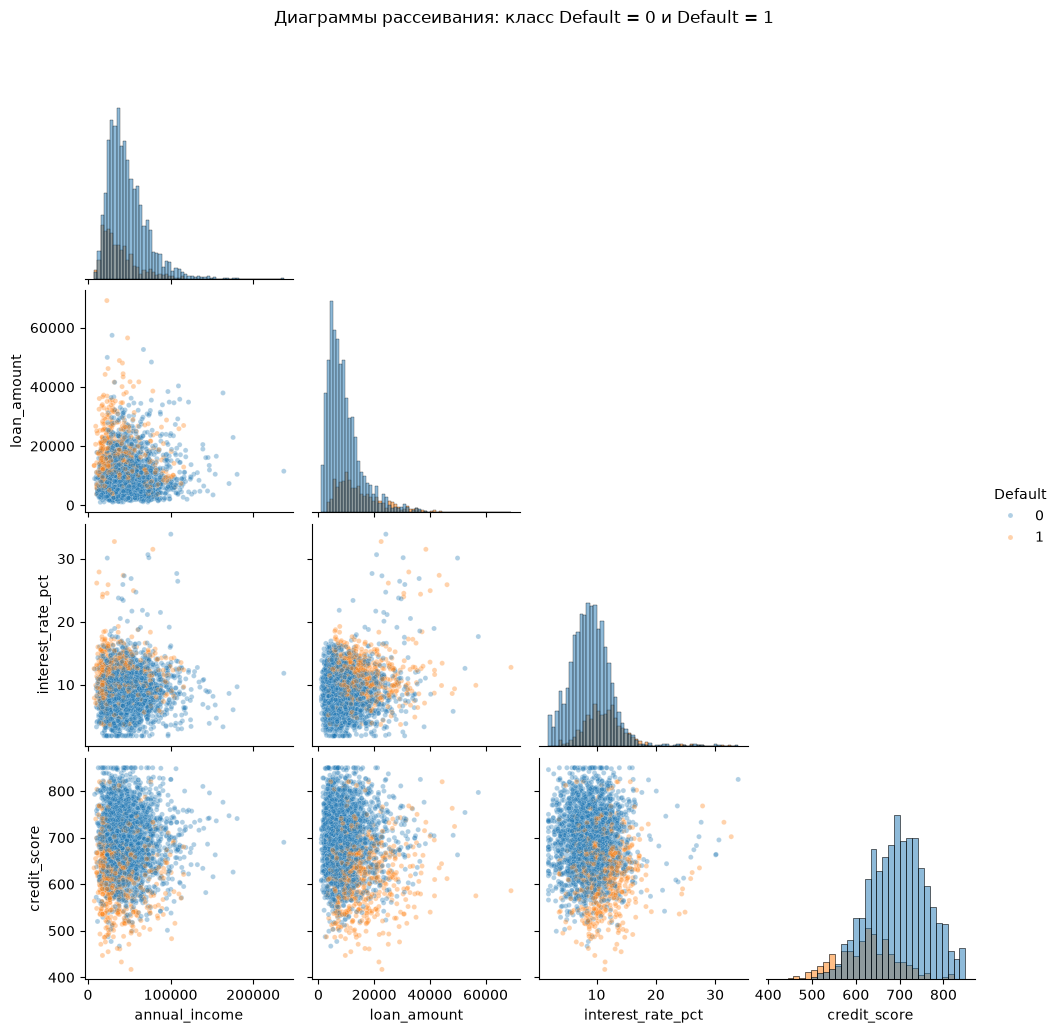

In [15]:
# Выбраны четыре информативных числовых признака,
# чтобы матрица не была перегружена большим числом диаграмм.
scatter_features = [
    'annual_income', 'loan_amount', 'interest_rate_pct', 'credit_score'
]

plot = sns.pairplot(
    df_bank, vars=scatter_features, hue='Default',
    diag_kind='hist', corner=True,
    plot_kws={'alpha': 0.35, 's': 13},
    height=2.5
)
plot.figure.suptitle('Диаграммы рассеивания: класс Default = 0 и Default = 1', y=1.03)
plt.show()

Разными цветами показаны кредиты без дефолта (`Default=0`) и с дефолтом (`Default=1`). На диаграммах заметно, что случаи дефолта чаще встречаются при **больших суммах кредита, более высоких ставках и меньшем кредитном рейтинге**. При этом классы частично перекрываются. Целевой класс используется **только для окраски точек**, но не для обучения кластеризаторов.

### 2.6 Стандартизация числовых признаков

*Подготовить числовые данные для алгоритмов, основанных на расстояниях.*

In [16]:
scaler_bank = StandardScaler()
X_bank_scaled = scaler_bank.fit_transform(X_bank)

df_bank_scaled = pd.DataFrame(
    X_bank_scaled, columns=numeric_features, index=df_bank.index
)
display(df_bank_scaled.describe().loc[['mean', 'std']].round(3))

,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
mean,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


После `StandardScaler` средние значения каждого признака близки к нулю, а стандартные отклонения — к единице. Одна и та же стандартизованная матрица `X_bank_scaled` будет использоваться для обоих методов, чтобы сравнение было корректным.

### 2.7 Выбор количества кластеров K-means: метод локтя и силуэт

*Подобрать число кластеров с помощью `inertia_` и коэффициента силуэта.*

,k,inertia,silhouette
0,1,21287.0000,NaN
1,2,18973.3754,0.1158
2,3,17159.1999,0.1183
3,4,15863.7890,0.1167
4,5,14852.9276,0.1089
5,6,13972.4514,0.1089
6,7,13228.6750,0.1101
7,8,12743.6941,0.1063


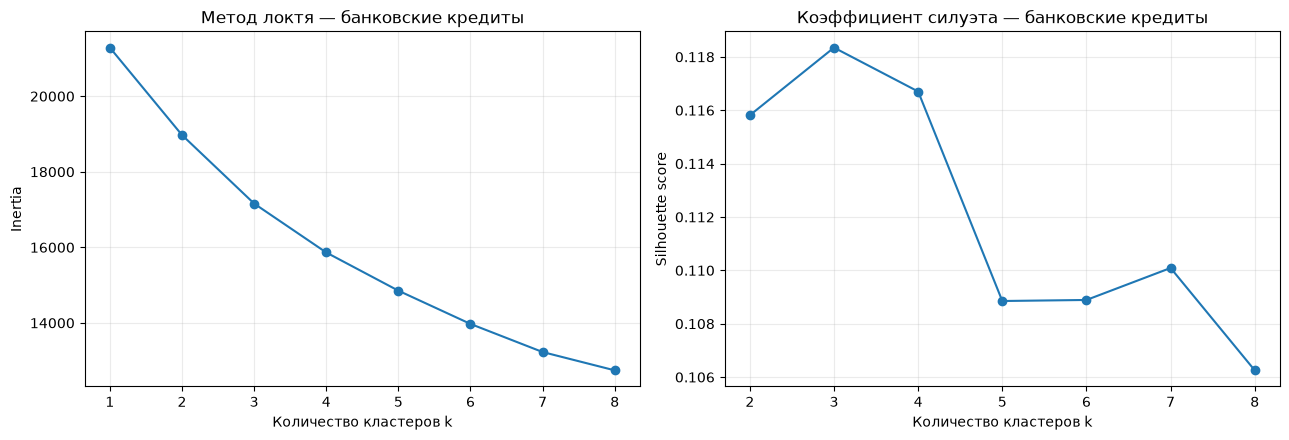

In [17]:
bank_kmeans_scores = []

for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_bank_scaled)
    bank_kmeans_scores.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X_bank_scaled, labels) if k > 1 else np.nan
    })

bank_scores_df = pd.DataFrame(bank_kmeans_scores)
display(bank_scores_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(bank_scores_df['k'], bank_scores_df['inertia'], marker='o')
axes[0].set_title('Метод локтя — банковские кредиты')
axes[0].set_xlabel('Количество кластеров k')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(bank_scores_df['k'])
axes[0].grid(alpha=0.25)

axes[1].plot(bank_scores_df['k'][1:], bank_scores_df['silhouette'][1:], marker='o')
axes[1].set_title('Коэффициент силуэта — банковские кредиты')
axes[1].set_xlabel('Количество кластеров k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_xticks(bank_scores_df['k'][1:])
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

График `inertia_` убывает при увеличении числа кластеров, но **чётко выраженного локтя нет**. Среди проверенных вариантов от **2 до 8 кластеров** наибольший коэффициент силуэта получен при **k=3** (около **0,1183**; для k=2 — около **0,1158**). Разница небольшая, поэтому идеального разделения здесь нет. Для дальнейшего анализа выбрано **три кластера**.

### 2.8 Кластеризация методом K-means при k=3

*Определить принадлежность объектов к кластерам и посмотреть распределение меток.*

In [18]:
kmeans_bank = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
labels_bank_kmeans = kmeans_bank.fit_predict(X_bank_scaled)

df_bank_kmeans = df_bank.copy()
df_bank_kmeans['cluster'] = labels_bank_kmeans

print('Число заёмщиков в кластерах K-means:')
display(df_bank_kmeans['cluster'].value_counts().sort_index())
print('Пример распределения конкретных объектов:')
display(df_bank_kmeans[
    ['age', 'annual_income', 'loan_amount', 'credit_score', 'Default', 'cluster']
].head(10))

Число заёмщиков в кластерах K-means:


cluster
0     513
1    1315
2    1213
Name: count, dtype: int64

Пример распределения конкретных объектов:


,age,annual_income,loan_amount,credit_score,Default,cluster
0,42,57272.0,8516.0,730.0,0,1
1,51,45786.0,13760.0,677.0,0,2
2,69,42359.0,2569.0,624.0,0,2
3,65,50709.0,13204.0,698.0,0,2
4,30,46272.0,7700.0,532.0,0,1
5,67,80366.0,6238.0,715.0,0,2
6,73,53841.0,10011.0,646.0,1,2
7,31,24441.0,6946.0,850.0,0,1
8,74,49362.0,3292.0,616.0,0,2
9,35,32341.0,3148.0,735.0,0,1


K-means распределил **3041 кредит** по трём группам. Сами номера кластеров не характеризуют риск и не должны интерпретироваться как заранее известные классы: содержательное значение определяется по средним показателям внутри каждой группы.

### 2.9 Средние характеристики и интерпретация кластеров K-means

*Подсчитать средние показатели числовых признаков каждого кластера и описать полученные группы.*

In [19]:
kmeans_cluster_means = (
    df_bank_kmeans.groupby('cluster')[numeric_features].mean().round(2)
)
kmeans_default_pct = (
    df_bank_kmeans.groupby('cluster')['Default'].mean().mul(100).round(1)
)

print('Средние значения числовых признаков в кластерах:')
display(kmeans_cluster_means)
print('Доля Default=1 по группам (для интерпретации, не для обучения):')
display(kmeans_default_pct.to_frame('Дефолты, %'))

Средние значения числовых признаков в кластерах:


,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
cluster,,,,,,,
0,48.33,42121.60,22200.03,11.79,47.42,630.78,4.18
1,33.51,46516.14,8266.70,9.12,47.46,694.73,4.51
2,61.28,46444.38,8432.49,8.79,48.07,688.01,4.74


Доля Default=1 по группам (для интерпретации, не для обучения):


,"Дефолты, %"
cluster,
0,57.5
1,12.7
2,13.0


По средним значениям выделяются три группы:

- **Кластер 0 (513 объектов)** — наиболее крупные кредиты (в среднем около **22 200 USD**), повышенная ставка (**11,8 %**) и более низкий кредитный рейтинг (**631**). Доля дефолтов составляет **57,5 %**.
- **Кластер 1 (1315 объектов)** — более молодые заёмщики (в среднем **33,5 года**), существенно меньшие суммы кредитов (около **8267 USD**). Доля дефолтов — примерно **12,7 %**.
- **Кластер 2 (1213 объектов)** — более старшие заёмщики (в среднем **61,3 года**), средняя сумма кредита около **8433 USD**. Доля дефолтов — около **13,0 %**.

Таким образом, K-means выделил одну группу с более высокой наблюдаемой долей дефолтов и две группы с меньшей долей. **`Default` не использовался при формировании кластеров**: это сопоставление выполнено после обучения.

### 2.10 Метрики качества K-means

*Вычислить внутреннюю метрику силуэта и несколько внешних метрик относительно известного класса `Default`.*

In [20]:
kmeans_metrics = {
    'Silhouette': silhouette_score(X_bank_scaled, labels_bank_kmeans),
    'ARI': adjusted_rand_score(y_default, labels_bank_kmeans),
    'AMI': adjusted_mutual_info_score(y_default, labels_bank_kmeans),
    'FMI': fowlkes_mallows_score(y_default, labels_bank_kmeans),
}

display(pd.Series(kmeans_metrics, name='Значение').round(4).to_frame())

,Значение
Silhouette,0.1183
ARI,0.1107
AMI,0.0932
FMI,0.5627


Коэффициент силуэта **0,1183** указывает на **слабое пространственное разделение** кластеров. Внешние индексы **ARI ≈ 0,1107** и **AMI ≈ 0,0932** показывают, что полученные три группы не совпадают с двумя заранее известными классами дефолта. Это закономерно: кластеризация основана на сходстве числовых признаков, а не на предсказании `Default`. Индекс FMI нельзя интерпретировать отдельно от остальных метрик, в особенности при неравномерном распределении исходных классов.

### 2.11 Иерархическая кластеризация: построение дендрограммы

*Применить метод `linkage()` с критерием `ward` и построить дендрограмму.*

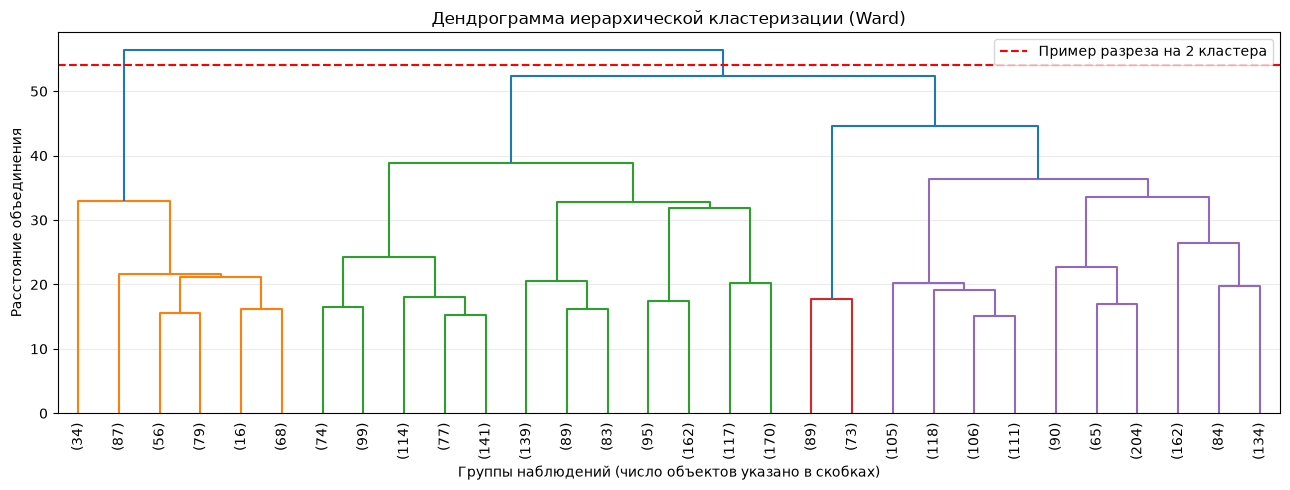

Расстояния последних объединений:
[36.42 38.89 44.6  52.43 56.33]


In [21]:
linked_bank = linkage(X_bank_scaled, method='ward')

plt.figure(figsize=(13, 5))
dendrogram(
    linked_bank,
    truncate_mode='lastp', p=30,
    leaf_rotation=90, show_leaf_counts=True
)
plt.axhline(y=54, color='red', linestyle='--', label='Пример разреза на 2 кластера')
plt.title('Дендрограмма иерархической кластеризации (Ward)')
plt.xlabel('Группы наблюдений (число объектов указано в скобках)')
plt.ylabel('Расстояние объединения')
plt.legend()
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print('Расстояния последних объединений:')
print(np.round(linked_bank[-5:, 2], 2))

На верхних уровнях дендрограммы видны крупные объединения групп. Поэтому можно рассматривать **два или три кластера** как разумные варианты разреза дерева. Для читаемости диаграмма усечена до последних 30 объединений (`truncate_mode='lastp'`), однако сама иерархия построена **по всем 3041 наблюдениям**. Красная горизонтальная линия показывает один из возможных уровней разделения на две группы.

### 2.12 Выбор количества кластеров агломеративного метода

*Сопоставить качество разбиения на 2, 3 и 4 кластера, чтобы уточнить выбор по дендрограмме.*

In [22]:
agglomerative_comparison = []

for k in [2, 3, 4]:
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X_bank_scaled)
    agglomerative_comparison.append({
        'Число кластеров': k,
        'Силуэт': silhouette_score(X_bank_scaled, labels)
    })

display(pd.DataFrame(agglomerative_comparison).round(4))

,Число кластеров,Силуэт
0,2,0.1890
1,3,0.0767
2,4,0.0772


Среди рассмотренных вариантов наибольший коэффициент силуэта получен для **двух кластеров (0,1890)**. При трёх или четырёх кластерах силуэт снижается примерно до **0,0767** и **0,0772**. С учётом дендрограммы и численной оценки далее используется **агломеративная модель с двумя кластерами**.

### 2.13 Обучение AgglomerativeClustering и характеристики кластеров

*Получить метки кластеров, определить группы объектов и вычислить средние показатели по каждому числовому признаку.*

In [23]:
agglomerative_bank = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels_bank_agglomerative = agglomerative_bank.fit_predict(X_bank_scaled)

df_bank_agglomerative = df_bank.copy()
df_bank_agglomerative['cluster'] = labels_bank_agglomerative

print('Размеры кластеров агломеративного метода:')
display(df_bank_agglomerative['cluster'].value_counts().sort_index())
print('Пример распределения объектов:')
display(df_bank_agglomerative[
    ['age', 'annual_income', 'loan_amount', 'credit_score', 'Default', 'cluster']
].head(10))
print('Средние значения числовых признаков:')
display(
    df_bank_agglomerative.groupby('cluster')[numeric_features].mean().round(2)
)
print('Доля Default=1 внутри кластеров:')
display(
    (df_bank_agglomerative.groupby('cluster')['Default'].mean() * 100)
    .round(1).to_frame('Дефолты, %')
)

Размеры кластеров агломеративного метода:


cluster
0    2701
1     340
Name: count, dtype: int64

Пример распределения объектов:


,age,annual_income,loan_amount,credit_score,Default,cluster
0,42,57272.0,8516.0,730.0,0,0
1,51,45786.0,13760.0,677.0,0,0
2,69,42359.0,2569.0,624.0,0,0
3,65,50709.0,13204.0,698.0,0,0
4,30,46272.0,7700.0,532.0,0,0
5,67,80366.0,6238.0,715.0,0,0
6,73,53841.0,10011.0,646.0,1,0
7,31,24441.0,6946.0,850.0,0,0
8,74,49362.0,3292.0,616.0,0,0
9,35,32341.0,3148.0,735.0,0,0


Средние значения числовых признаков:


,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
cluster,,,,,,,
0,47.11,45617.01,8934.45,9.17,48.01,685.09,4.50
1,46.96,46772.34,24576.45,11.58,45.18,650.90,4.89


Доля Default=1 внутри кластеров:


,"Дефолты, %"
cluster,
0,17.0
1,47.4


Агломеративный метод сформировал две неравные группы:

- **Кластер 0 (2701 объект)** — средняя сумма кредита около **8934 USD**, ставка **9,2 %**, кредитный рейтинг около **685**. Доля дефолтов — примерно **17,0 %**.
- **Кластер 1 (340 объектов)** — заметно более крупные кредиты (около **24 577 USD**), более высокая ставка (**11,6 %**) и меньший кредитный рейтинг (**651**). Доля дефолтов — примерно **47,4 %**.

Вторая группа значительно меньше первой и имеет более высокую долю дефолтов. Эти проценты рассчитаны **после кластеризации** с использованием исходного `Default`.

### 2.14 Метрики качества агломеративной кластеризации

*Вычислить те же метрики, что и для K-means.*

In [24]:
agglomerative_metrics = {
    'Silhouette': silhouette_score(X_bank_scaled, labels_bank_agglomerative),
    'ARI': adjusted_rand_score(y_default, labels_bank_agglomerative),
    'AMI': adjusted_mutual_info_score(y_default, labels_bank_agglomerative),
    'FMI': fowlkes_mallows_score(y_default, labels_bank_agglomerative),
}

display(pd.Series(agglomerative_metrics, name='Значение').round(4).to_frame())

,Значение
Silhouette,0.1890
ARI,0.1590
AMI,0.0547
FMI,0.7782


Коэффициент силуэта равен примерно **0,1890**, что выше результата K-means при k=3. Показатель **ARI ≈ 0,1590** также выше, хотя абсолютное значение остаётся небольшим. Индекс **AMI ≈ 0,0547**, напротив, ниже результата K-means. Следовательно, один метод не превосходит другой по всем критериям одновременно.

### 2.15 Сравнение методов и выбор целесообразного варианта

В условиях данного набора данных:

- **K-means (k=3)** даёт более подробную сегментацию заёмщиков: группа с повышенной долей дефолтов, более молодые заёмщики и более возрастные заёмщики. Его коэффициент силуэта — **0,1183**.
- **AgglomerativeClustering (k=2)** выделяет две группы, одна из которых отличается значительно большей суммой кредита и более высокой долей дефолтов. Его коэффициент силуэта — **0,1890**.

**Для более отчётливого разделения объектов по использованным числовым характеристикам целесообразнее выбрать агломеративную кластеризацию с двумя кластерами**, поскольку её коэффициент силуэта выше. Если необходима именно более детальная сегментация на три группы, полезен K-means. При этом оба алгоритма показывают достаточно низкие абсолютные значения силуэта, а полученные кластеры нельзя считать точным предсказанием дефолта.

## 3. Вывод

В ходе лабораторной работы были изучены методы кластеризации K-means и агломеративная иерархическая кластеризация. Для искусственного набора данных из **300 наблюдений** выполнена стандартизация признаков и построены модели для двух, трёх и четырёх кластеров. Наиболее удачным оказалось разделение на **три кластера**: коэффициент силуэта составил **0,7097**, а метод локтя подтвердил выбор этого количества групп.

Во второй части исследован набор `bank_loan_default.csv`, содержащий **3041 запись о кредитах**. Пропуски и полные дубликаты не обнаружены. Для кластеризации отобраны **семь числовых признаков** и выполнена их стандартизация; целевой класс `Default` не включался в обучение. Для K-means выбран вариант с **тремя кластерами** (силуэт **0,1183**). Он выделил группу с повышенной средней суммой кредита и долей дефолтов около **57,5 %**.

Иерархическая кластеризация методом Уорда разделила заёмщиков на **две группы** с коэффициентом силуэта **0,1890**. В меньшем кластере из **340 кредитов** средняя сумма кредита выше, а доля дефолтов составляет около **47,4 %**. По критерию силуэта для данного набора данных агломеративный метод оказался предпочтительнее K-means при k=3. Однако небольшие значения внешних метрик и силуэта показывают, что полученные группы не совпадают полностью с исходными классами дефолта и частично перекрываются. Кластеризация позволяет изучать группы похожих кредитов, но сама по себе не заменяет модель прогнозирования невозврата.